In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from time import perf_counter

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold,cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix, classification_report
)
import warnings
warnings.filterwarnings("ignore")

In [2]:
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns = dataset.feature_names)
y= pd.Series(dataset.target, name='target')
print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

print(X.head())
print(y.value_counts())

Dataset Shape: (569, 30)
Target Shape: (569,)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  

In [3]:
# explore the dataset
print(X.info())
print(X.describe())

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [4]:
print(X.isnull().sum().sum())

0


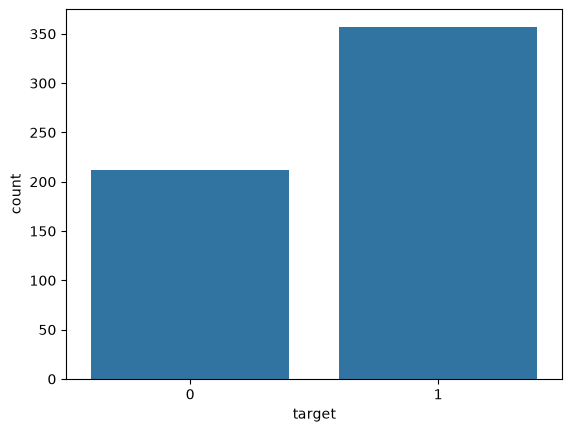

In [5]:
sns.countplot(x=y)
plt.show()

In [6]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler",StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),

    "Decision Tree" : Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": Pipeline([
        ("model", GaussianNB())
    ]),
    
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel='rbf'))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(n_estimators=100, random_state=42,n_jobs=-1))
    ]),

    "Gradient Boosting": Pipeline([
        ("model", GradientBoostingClassifier(random_state=42))
    ])
    
}

In [8]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [9]:
scoring = {
    "accuracy": "accuracy",
    "precision":"precision",
    "recall":'recall',
    "f1":"f1",
    "roc_auc": "roc_auc"
}

In [11]:
cv_results =[]
for name,model in models.items():
    scores = cross_validate(model,X_train,y_train,cv=cv,scoring=scoring, return_train_score=False,n_jobs=-1)
    result = {
        "Model": name
    }

    for metric in scoring:
        result[f"{metric}_mean"]= scores[f"test_{metric}"].mean()
        result[f"{metric}_std"]= scores[f"test_{metric}"].std()

    result['cv_fit_time_mean'] = scores['fit_time'].mean() # avg time a model takes to train on one training fold
    result['cv_score_time_mean'] = scores['score_time'].mean() # avg time a trained model takes to make predictions and calculate ecaluation metrics on one valdiataion fold
    cv_results.append(result)

cv_df = pd.DataFrame(cv_results)
print(cv_df.round(4))

                 Model  accuracy_mean  accuracy_std  precision_mean  \
0  Logistic Regression         0.9780        0.0098          0.9795   
1        Decision Tree         0.9165        0.0179          0.9528   
2                  KNN         0.9626        0.0112          0.9592   
3          Naive Bayes         0.9407        0.0247          0.9422   
4                  SVM         0.9692        0.0146          0.9728   
5        Random Forest         0.9626        0.0179          0.9755   
6    Gradient Boosting         0.9516        0.0149          0.9617   

   precision_std  recall_mean  recall_std  f1_mean  f1_std  roc_auc_mean  \
0         0.0162       0.9860      0.0131   0.9825  0.0078        0.9959   
1         0.0203       0.9123      0.0192   0.9319  0.0144        0.9179   
2         0.0129       0.9825      0.0192   0.9705  0.0091        0.9882   
3         0.0251       0.9649      0.0192   0.9533  0.0192        0.9877   
4         0.0225       0.9789      0.0131   0.9756 

In [12]:
# Logistic Regression performed well

In [25]:
# evaluate the model in test dataset
def evaluate_model(model, X_train,y_train,X_test,y_test):
    start = perf_counter()
    model.fit(X_train,y_train)
    end= perf_counter()
    training_time = end - start

    # prediction time
    start = perf_counter()
    y_pred = model.predict(X_test)
    end = perf_counter()
    predicting_time = end - start

    #svm doesn't use predict_proba
    if hasattr(model,"decision_function"):
        y_score = model.decision_function(X_test)
    else:
        y_score = model.predict_proba(X_test)[:,1]

    
    #calculate metrics:
    results = {
        "accuracy" : accuracy_score(y_test,y_pred),
        "recall": recall_score(y_test,y_pred),
        "precision": precision_score(y_test,y_pred),
        "f1": f1_score(y_test,y_pred),
        "roc_auc": roc_auc_score(y_test, y_score),
        "training_time_s": training_time,
        "prediction_time_s":predicting_time,
        "prediction_time_per_sample_ms": (predicting_time/ len(X_test)) * 1000
    }

    return results
    

In [27]:
test_results= []
for name, model in models.items():
    results = evaluate_model(model,X_train, y_train,X_test,y_test) 
    results['Model'] = name
    test_results.append(results)
test_df = pd.DataFrame(test_results)
print(test_df)

   accuracy    recall  precision        f1   roc_auc  training_time_s  \
0  0.982456  0.986111   0.986111  0.986111  0.995370         0.125599   
1  0.912281  0.902778   0.955882  0.928571  0.915675         0.023596   
2  0.956140  0.972222   0.958904  0.965517  0.978836         0.010502   
3  0.938596  0.958333   0.945205  0.951724  0.987765         0.007599   
4  0.982456  0.986111   0.986111  0.986111  0.995040         0.018783   
5  0.956140  0.972222   0.958904  0.965517  0.993717         0.434848   
6  0.956140  0.986111   0.946667  0.965986  0.990741         0.849446   

   prediction_time_s  prediction_time_per_sample_ms                Model  
0           0.012875                       0.112940  Logistic Regression  
1           0.002411                       0.021149        Decision Tree  
2           0.007306                       0.064088                  KNN  
3           0.002685                       0.023554          Naive Bayes  
4           0.005029                    

In [28]:
# logisting regression: result best, but take more time i n training and prediction
# I would choose Logistic Regression as the baseline to carry forward, with SVM as a serious competitor..
# if i need to deploy in low-power edge devicel then i would like to lean towards SVM.

In [30]:
# creating the final comparision table by combining both cv and testing scores:

comparison = cv_df.merge(test_df, on = 'Model')
print(comparison)

                 Model  accuracy_mean  accuracy_std  precision_mean  \
0  Logistic Regression       0.978022      0.009829        0.979472   
1        Decision Tree       0.916484      0.017855        0.952811   
2                  KNN       0.962637      0.011207        0.959179   
3          Naive Bayes       0.940659      0.024670        0.942185   
4                  SVM       0.969231      0.014579        0.972750   
5        Random Forest       0.962637      0.017855        0.975519   
6    Gradient Boosting       0.951648      0.014906        0.961725   

   precision_std  recall_mean  recall_std   f1_mean    f1_std  roc_auc_mean  \
0       0.016229     0.985965    0.013129  0.982544  0.007752      0.995872   
1       0.020280     0.912281    0.019218  0.931901  0.014435      0.917905   
2       0.012938     0.982456    0.019218  0.970489  0.009111      0.988235   
3       0.025081     0.964912    0.019218  0.953280  0.019243      0.987719   
4       0.022525     0.978947    0.0

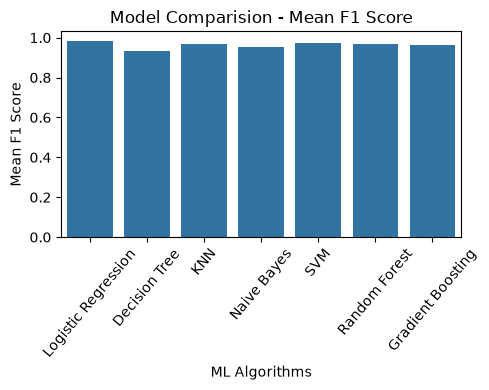

In [36]:
# compare F1 -scores

plt.figure(figsize=(5,4))
sns.barplot(data=cv_df,x='Model',y='f1_mean')
plt.title("Model Comparision - Mean F1 Score")
plt.xlabel("ML Algorithms")
plt.ylabel("Mean F1 Score")
plt.xticks(rotation=50)
plt.tight_layout()
plt.show()

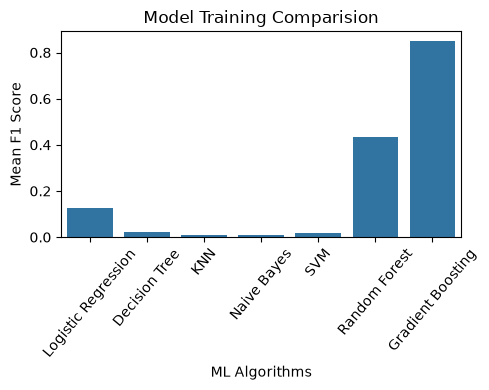

In [38]:
# compare training time

plt.figure(figsize=(5,4))
sns.barplot(data=test_df,x='Model',y='training_time_s')
plt.title("Model Training Comparision")
plt.xlabel("ML Algorithms")
plt.ylabel("Mean F1 Score")
plt.xticks(rotation=50)
plt.tight_layout()
plt.show()

In [40]:
comparison.to_csv("results/model_comparison.csv", index = False)
print("Comparison resuts saved successfully.")

Comparison resuts saved successfully.
